# CBIS-DDSM Data Preparation

This notebook prepares the CBIS-DDSM mammography dataset for the experiments in `mammo_semcom`.

The dataset ZIP file is already available in Google Drive, so this notebook extracts that copy and does not download the dataset again.

The preparation steps are:
1. Mount Google Drive and locate the ZIP file.
2. Extract the dataset.
3. Build an index of the available images.
4. Match images with the case metadata and masks.
5. Create the processed cache and patient-level data splits.
6. Check a few samples.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

/content/drive/MyDrive/mammo_semcom_data/CBIS-DDSM.zip


## 1. Set the project and dataset paths

Keep the project code and the dataset ZIP in the locations below, or update the paths to match your Drive.

For example:

- `MyDrive/mammo_semcom/` contains the project code (`src/`).
- `MyDrive/mammo_semcom_data/CBIS-DDSM.zip` contains the dataset archive.
- `mammo_semcom_work/` will store the cache, figures and other generated files.

In [7]:
from pathlib import Path
import os

CODE_DIR = Path("/content/drive/MyDrive/mammo_semcom")
ZIP_PATH = Path("/content/drive/MyDrive/mammo_semcom_data/CBIS-DDSM.zip")
WORK_DIR = Path("/content/drive/MyDrive/mammo_semcom_work")

# Extracting to Colab storage is usually faster than processing directly from Drive.
EXTRACT_DIR = Path("/content/cbis_ddsm")

MAX_IMAGES = 150   # Start with 150 images to check the pipeline. Use 0 for all images.

assert CODE_DIR.exists(), f"Project folder not found: {CODE_DIR}"
assert (CODE_DIR / "src").exists(), f"'src' folder not found inside: {CODE_DIR}"
assert ZIP_PATH.exists(), f"Dataset ZIP not found: {ZIP_PATH}"

print("Project folder:", CODE_DIR)
print("Dataset ZIP:", ZIP_PATH)
print("Working folder:", WORK_DIR)
print("Maximum images:", "all" if MAX_IMAGES == 0 else MAX_IMAGES)

Project folder: /content/drive/MyDrive/mammo_semcom
Dataset ZIP: /content/drive/MyDrive/mammo_semcom_data/CBIS-DDSM.zip
Working folder: /content/drive/MyDrive/mammo_semcom_work
Maximum images: 150


## 2. Install the required packages and load the project modules

In [8]:
%cd /content

!pip -q install pydicom

import sys
sys.path.insert(0, str(CODE_DIR))

from src.config import Cfg
from src import data

cfg = Cfg(work_dir=str(WORK_DIR), max_images=MAX_IMAGES).ensure()
print("Project modules loaded.")

/content
Project modules loaded.


## 3. Extract the dataset

The archive is extracted only if it has not already been extracted. If you need to start extraction again, delete the extraction folder first.

In [9]:
import zipfile

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

if not any(EXTRACT_DIR.iterdir()):
    print("Extracting dataset. This may take a while...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
        zip_file.extractall(EXTRACT_DIR)
    print("Extraction complete.")
else:
    print("An extraction folder already exists; using the existing files.")

print("Top-level extracted items:")
for item in list(EXTRACT_DIR.iterdir())[:20]:
    print(item.name)

Extracting dataset. This may take a while...
Extraction complete.
Top-level extracted items:
jpeg
csv


## 4. Find the dataset root

ZIP files sometimes contain an extra parent folder. This cell searches for the folder containing the CBIS-DDSM metadata CSV files and sets it as the dataset root.

In [10]:
csv_files = list(EXTRACT_DIR.rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        "No CSV files were found after extraction. Check that the correct CBIS-DDSM ZIP was selected."
    )

# Use the common parent folder of the extracted CSV files as the initial dataset root.
# The project helper will inspect the folder structure in the next step.
csv_parent = Path(os.path.commonpath([str(p.parent) for p in csv_files]))
cfg.cbis_root = str(EXTRACT_DIR)

print("CSV files found:", len(csv_files))
print("Example CSV files:")
for path in csv_files[:10]:
    print(path.relative_to(EXTRACT_DIR))
print("Dataset root:", cfg.cbis_root)

CSV files found: 6
Example CSV files:
csv/mass_case_description_train_set.csv
csv/calc_case_description_train_set.csv
csv/meta.csv
csv/calc_case_description_test_set.csv
csv/dicom_info.csv
csv/mass_case_description_test_set.csv
Dataset root: /content/cbis_ddsm


## 5. Inspect the metadata and image files

In [11]:
case_csvs = data.find_case_csvs(cfg.cbis_root)
print("Case/metadata CSV files:")
for path in case_csvs:
    print(path)

if not case_csvs:
    raise RuntimeError(
        "The project could not identify the CBIS-DDSM case CSV files. "
        "Check the extracted folder structure and the dataset ZIP."
    )

from collections import Counter

extensions = Counter(
    p.suffix.lower()
    for p in EXTRACT_DIR.rglob("*")
    if p.is_file()
)
print("\nFile extensions:")
for extension, count in extensions.most_common():
    print(f"{extension or '[no extension]'}: {count}")

Case/metadata CSV files:
('mass', 'train')
('calc', 'train')
('calc', 'test')
('mass', 'test')

File extensions:
.jpg: 10237
.csv: 6


## 6. Index the mammogram images

The image index records the image files available in the extracted dataset. It is saved in the project cache so it can be reused.

In [12]:
index_path = cfg.path("cache", "image_index.csv")
dcm_index = data.index_images(
    cfg.cbis_root,
    index_path,
    cfg.n_workers
)

print("Indexed image files:", len(dcm_index))
print("Index saved to:", index_path)

Indexed image files: 10237
Index saved to: /content/drive/MyDrive/mammo_semcom_work/cache/image_index.csv


## 7. Check image and metadata matching

In [13]:
data.diagnose_matching(cfg, dcm_index)

image_file_path           : 100.0% of 3568 rows matched an image file
cropped_image_file_path   : 100.0% of 3568 rows matched an image file
roi_mask_file_path        : 100.0% of 3568 rows matched an image file
example CSV path     : 'Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm'
example series ids   : ['1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152454291132', '1.3.6.1.4.1.9590.100.1.2.100131208110604806117271735422083351547', '1.3.6.1.4.1.9590.100.1.2.100522099512256189513864912954167862869']


## 8. Build the manifest

The manifest brings together the image paths and the available case information. It is saved before preprocessing so that the matching results can be inspected later.

In [14]:
manifest = data.build_manifest(cfg, dcm_index)

manifest_path = cfg.path("cache", "manifest.csv")
manifest.to_csv(manifest_path, index=False)

print("Manifest rows:", len(manifest))
print("Manifest saved to:", manifest_path)
display(manifest.head())

CSV rows: 3568 | rows whose DICOM files were found: 3567 | dropped: 1
Manifest rows: 3567
Manifest saved to: /content/drive/MyDrive/mammo_semcom_work/cache/manifest.csv


,patient_id,side,view,lesion_type,split_official,abnormality_id,pathology,label,subtlety,assessment,full_file,roi_file,crop_file
0,P_00001,LEFT,CC,mass,train,1,MALIGNANT,1,4,4,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...
1,P_00001,LEFT,MLO,mass,train,1,MALIGNANT,1,4,4,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...
2,P_00004,LEFT,CC,mass,train,1,BENIGN,0,3,4,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...
3,P_00004,LEFT,MLO,mass,train,1,BENIGN,0,3,4,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...
4,P_00004,RIGHT,MLO,mass,train,1,BENIGN,0,5,4,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...,/content/cbis_ddsm/jpeg/1.3.6.1.4.1.9590.100.1...


## 9. Create the processed cache

This step reads the selected images and masks and creates the cache used by the later notebooks. The first run may take some time.

In [15]:
images, masks, images_df, abn_df = data.build_cache(cfg, manifest)

print("Image array shape:", getattr(images, "shape", None))
print("Mask array shape:", getattr(masks, "shape", None))
print("Image records:", len(images_df))
print("Abnormality records:", len(abn_df))

preprocessed 150 / 150 mammograms
Image array shape: (150, 768, 512)
Mask array shape: (150, 768, 512)
Image records: 150
Abnormality records: 171


## 10. Create patient-level data splits

The split function in the project code creates the training, validation and test assignments. Keeping the split at patient level helps prevent images from the same patient from appearing in different sets.

In [16]:
images_df, abn_df = data.make_splits(images_df, abn_df, cfg)

print("Image split counts:")
if "split" in images_df.columns:
    display(images_df["split"].value_counts(dropna=False))
else:
    print("No 'split' column found in images_df; inspect the returned dataframe.")

print("\nAbnormality records:", len(abn_df))

Image split counts:


,count
split,
train,106
test,22
val,22



Abnormality records: 171


## 11. Quality-control summary and save the configuration

In [17]:
data.qc_summary(images_df, abn_df)
cfg.save()

print("Data preparation finished.")
print("Processed files are stored in:", WORK_DIR)

images: 150 | abnormalities: 171 | patients: 145
mixed-label images (excluded from image-level evaluation): 0
       count  malignant_frac
split                       
test      22           0.500
train    106           0.415
val       22           0.318
             count   mean
lesion_type              
calc            95  0.284
mass            76  0.487
lesion area at working resolution (pixels): {'min': 58.0, '50%': 1920.0, 'max': 164099.0}
Data preparation finished.
Processed files are stored in: /content/drive/MyDrive/mammo_semcom_work


## 12. View a few processed samples

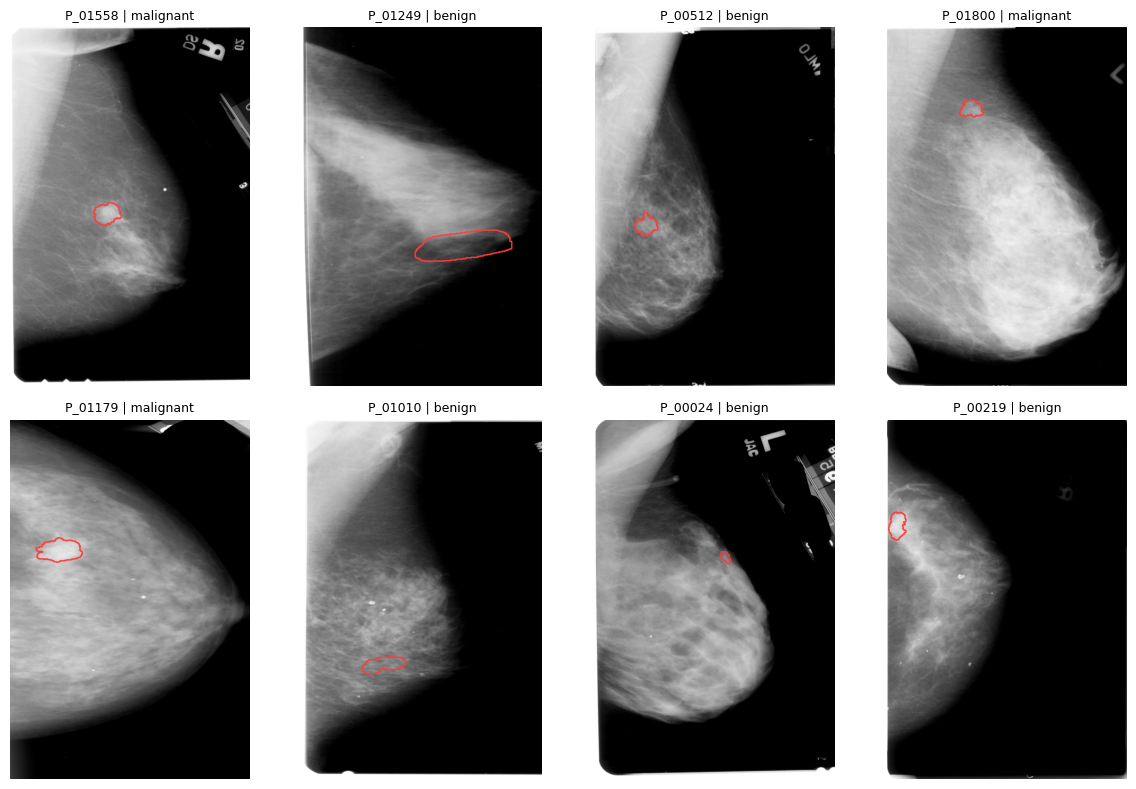

In [18]:
from src import viz

viz.show_samples(
    images,
    masks,
    images_df,
    n=8,
    path=cfg.path("figures", "00_samples.png")
)

## Notes

- `MAX_IMAGES = 150` is useful for checking that the pipeline runs correctly. It does not change the ZIP file or extract only 150 images; the ZIP archive is extracted in full.
- After the test run works, change `MAX_IMAGES` to `0` and rerun the preparation steps to process the full dataset.
- The raw ZIP is read from Google Drive, while the extracted files are placed in Colab storage. If the Colab runtime disconnects, the extracted folder may be lost, but the original ZIP remains in Drive.
- The project folder must contain the `src` package and the functions used above (`config.py`, `data.py` and `viz.py`). This notebook uses those project modules rather than replacing their implementation.
- Dataset source: CBIS-DDSM, originally described by Lee et al., *Scientific Data* (2017), DOI: 10.7937/K9/TCIA.2016.7O02S9CY. The Kaggle version is a redistributed copy; cite the dataset source and the Kaggle distribution used in your project.